In [5]:
import os
import pandas as pd

matches = []
for root, dirs, files in os.walk("/content/drive/MyDrive"):
  if "datasetsmall.csv" in files:
    matches.append(os.path.join(root, "datasetsmall.csv"))

print("Found files:", matches)

if matches:
  CSV_PATH = matches[0]
  df = pd.read_csv(CSV_PATH)
  print("Loaded from:", CSV_PATH)
  print("Loaded dataset shape:", df.shape)
  display(df.head())
else:
  print("datasetsmall.csv was not found in /content/drive/MyDrive.")

Found files: ['/content/drive/MyDrive/GRID GUARD/datasetsmall.csv']
Loaded from: /content/drive/MyDrive/GRID GUARD/datasetsmall.csv
Loaded dataset shape: (25863, 28)


,01/01/2014,01/02/2014,01/03/2014,01/04/2014,01/05/2014,01/06/2014,01/07/2014,01/08/2014,01/09/2014,01/10/2014,...,1/19/2014,1/20/2014,1/21/2014,1/22/2014,1/23/2014,1/24/2014,1/25/2014,1/26/2014,CONS_NO,FLAG
0,2401.0,2500.0,2674.0,2432.00,2231.00,1942.00,2752.00,1244.00,2069.0,2360.0,...,1774.00,2089.0,1300.0,2419.0,2462.0,1177.00,340.00,2272.00,A0E791400CF1C48C43DC26A68227854A,1
1,3318.0,282.0,540.0,5670.00,4854.00,4170.00,4848.00,3546.00,4416.0,3966.0,...,3876.00,3228.0,3054.0,3840.0,1422.0,1956.00,1380.00,96.00,B415F931D3BFB17ACEF48BC648B04FC2,1
2,1020.8,1097.4,1377.4,1408.80,1414.80,1387.40,1444.60,1325.00,1461.6,1253.2,...,1214.60,1285.4,1279.6,1188.6,1362.6,1286.00,1267.60,1444.00,DE8E1EAE4E578C0CEF92D1E23499888F,1
3,0.0,1183.8,1190.4,1183.80,0.00,1154.40,1166.40,1183.80,1169.4,1174.2,...,0.00,1072.8,1090.8,1090.2,1101.0,1079.40,1121.40,1145.40,2952491E940C9040B188B3C9095910D6,0
4,1445.7,1348.2,1281.9,1276.35,1219.95,1289.85,1298.55,1326.15,1410.6,1376.7,...,1331.85,1392.9,1213.2,1463.1,1405.5,1240.05,1190.25,1455.45,DBEED8FD0E7F5E0D1BAF1F86F4983459,1


Target column: FLAG
Total missing values before cleaning: 125

Class distribution:
FLAG
0    23741
1     2122
Name: count, dtype: int64
Theft rate (%): 8.2
Missing values after cleaning: 0


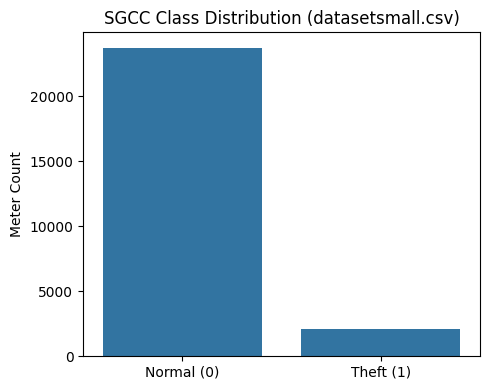

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Identify target column (FLAG if present, else last column)
target_col = "FLAG" if "FLAG" in df.columns else df.columns[-1]
print("Target column:", target_col)
print("Total missing values before cleaning:", int(df.isna().sum().sum()))
print("\nClass distribution:")
print(df[target_col].value_counts(dropna=False))
print("Theft rate (%):", round(df[target_col].mean() * 100, 2))

# Extract target and clean daily meter reading columns
y = pd.to_numeric(df[target_col], errors="coerce").fillna(0).astype(int).values
drop_cols = [c for c in ["FLAG", "CONS_NO", target_col] if c in df.columns]
readings = (
    df.drop(columns=drop_cols)
    .apply(pd.to_numeric, errors="coerce")
    .interpolate(axis=1, limit_direction="both")
    .fillna(0.0)
    .clip(lower=0.0)
)
print("Missing values after cleaning:", int(readings.isna().sum().sum()))

plt.figure(figsize=(5, 4))
sns.countplot(x=y)
plt.xticks([0, 1], ["Normal (0)", "Theft (1)"])
plt.title("SGCC Class Distribution (datasetsmall.csv)")
plt.ylabel("Meter Count")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split

vals = readings.values
mean_kwh = np.mean(vals, axis=1) + 1e-5
std_kwh = np.std(vals, axis=1)
max_kwh = np.max(vals, axis=1)

mid = max(1, vals.shape[1] // 2)
first_half_mean = np.mean(vals[:, :mid], axis=1) + 1e-5
second_half_mean = np.mean(vals[:, mid:], axis=1) + 1e-5
p25_kwh = np.percentile(vals, 25, axis=1)

night_usage_ratio = np.clip(p25_kwh / mean_kwh, 0.0, 1.0)
spike_factor = np.clip(max_kwh / mean_kwh, 1.0, 10.0)
phase_imbalance = np.clip(np.abs(second_half_mean - first_half_mean) / mean_kwh, 0.0, 1.0)
load_mismatch = np.clip(std_kwh / mean_kwh, 0.0, 2.0)

feature_names = ["night_usage_ratio", "spike_factor", "phase_imbalance", "load_mismatch"]
X = np.column_stack([night_usage_ratio, spike_factor, phase_imbalance, load_mismatch])
features_df = pd.DataFrame(X, columns=feature_names)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
display(features_df.describe().T[["mean", "std", "min", "50%", "max"]])

Train shape: (20690, 4) | Test shape: (5173, 4)


,mean,std,min,50%,max
night_usage_ratio,0.525214,0.401424,0.0,0.734048,1.0
spike_factor,2.502339,2.260810,1.0,1.654616,10.0
phase_imbalance,0.284271,0.331461,0.0,0.143252,1.0
load_mismatch,0.538719,0.566784,0.0,0.344307,2.0


,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,Logistic Regression,51.13,10.03,62.26,17.28,0.5653
1,Decision Tree,69.26,10.39,36.08,16.14,0.5563
2,Gradient Boosting,91.76,0.00,0.00,0.00,0.5865
3,Random Forest,74.91,11.26,29.95,16.37,0.5746



--- Random Forest Classification Report ---
              precision    recall  f1-score   support

  Normal (0)       0.93      0.79      0.85      4749
   Theft (1)       0.11      0.30      0.16       424

    accuracy                           0.75      5173
   macro avg       0.52      0.54      0.51      5173
weighted avg       0.86      0.75      0.80      5173



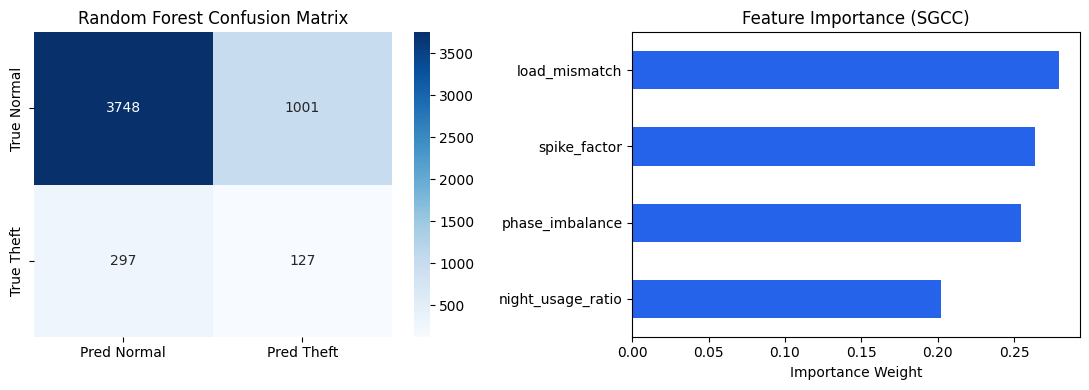

[OK] Saved theft_model_colab.pkl to Drive.


In [8]:
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=500, random_state=42),
    ),
    "Decision Tree": DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, max_depth=8, class_weight="balanced", random_state=42, n_jobs=-1
    ),
}

rows = []
trained = {}
for name, clf in models.items():
    clf.fit(X_train, y_train)
    trained[name] = clf
    pred = clf.predict(X_test)
    prob = clf.predict_proba(X_test)[:, 1]
    rows.append({
        "Model": name,
        "Accuracy (%)": round(accuracy_score(y_test, pred) * 100, 2),
        "Precision (%)": round(precision_score(y_test, pred, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(y_test, pred, zero_division=0) * 100, 2),
        "F1-Score (%)": round(f1_score(y_test, pred, zero_division=0) * 100, 2),
        "ROC-AUC": round(roc_auc_score(y_test, prob), 4),
    })

display(pd.DataFrame(rows))

rf = trained["Random Forest"]
y_pred_rf = rf.predict(X_test)
cm = confusion_matrix(y_test, y_pred_rf)
print("\n--- Random Forest Classification Report ---")
print(classification_report(y_test, y_pred_rf, target_names=["Normal (0)", "Theft (1)"]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Pred Normal", "Pred Theft"],
    yticklabels=["True Normal", "True Theft"],
    ax=axes[0],
)
axes[0].set_title("Random Forest Confusion Matrix")

pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=True).plot(
    kind="barh", color="#2563eb", ax=axes[1]
)
axes[1].set_title("Feature Importance (SGCC)")
axes[1].set_xlabel("Importance Weight")

plt.tight_layout()
plt.show()

# Save a permanent copy of the notebook model in Google Drive
joblib.dump(rf, "/content/drive/MyDrive/GRID GUARD/theft_model_colab.pkl")
print("[OK] Saved theft_model_colab.pkl to Drive.")